## Linear regessions

<img src="../data/regression-gif.gif" alt="alt text" width="300" height="200">

A regression is a way to describe how two (or more) things are related to each other. This notebook performs a simple linear regression. The notebook was adapted from [investigate.ai](https://investigate.ai/regression/) and [Dr. Tehreem Qasim](https://www.kaggle.com/code/tehreemkhan111/simple-linear-regression).



In [3]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.6 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached wrapt-2.6.0.dev1-cp314-cp314-macosx_11_0_arm64.whl.metadata (7.6 kB)
Using cached statsmodels-0.15.0-cp314-cp314-macosx_11_0_arm64.whl (11.6 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
Using cached wrapt-2.6.0.dev1-cp314-cp314-macosx_11_0_arm64.whl (106 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [5]:
import pandas as pd
import statsmodels.api as sm

### Performing a linear regression
First we will load our data

In [7]:
df = pd.read_csv('../data/salary_data.csv')
print(len(df))

30


In [8]:
df.head()

,YearsExperience,Salary,promoted
0,1.1,39343.0,0
1,1.3,46205.0,0
2,1.5,37731.0,0
3,2.0,43525.0,1
4,2.2,39891.0,0


Using the library statsmodels we can run linear regressions with dataframes. 

In [10]:
X = df["YearsExperience"]
y = df["Salary"]

# Use OLS to analyze the regression
model = sm.OLS(y, X)
results = model.fit()

Below we do two things: 
We define `YearsExperience` as the dependent variable. 

Ordinary Least Squares function from the statsmodels library. OLS is a common technique used in analyzing linear regression. In brief, it compares the difference between individual points in your data set and the predicted best fit line to measure the amount of error produced. (Source: [Medium](https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a)).

#### Examining our results

We stored out regression in a variable called `results`. Now we can look at the results but using the `.summary()` function to print out the entire regression result.



In [12]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                 Salary   R-squared (uncentered):                   0.973
Model:                            OLS   Adj. R-squared (uncentered):              0.972
Method:                 Least Squares   F-statistic:                              1048.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):                    2.56e-24
Time:                        16:14:38   Log-Likelihood:                         -327.28
No. Observations:                  30   AIC:                                      656.6
Df Residuals:                      29   BIC:                                      658.0
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
YearsExperience  1.325e+04    409.401     32.376      0.000    1.24e+04    1.41e+04
==============================================================================
Omnibus:                        0.610   Durbin-Watson:                   0.323
Prob(Omnibus):                  0.737   Jarque-Bera (JB):                0.671
Skew:                          -0.121   Prob(JB):                        0.715
Kurtosis:                       2.308   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### How to interpret your results


Our dependent variable is **Salary**, meaning we were interested in how much our Salary is dependent on the number of years. The information below is a summary of this [Medium post](https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a), this [Mediun post](https://medium.com/analytics-vidhya/how-to-interpret-result-from-linear-regression-3f7ae7679ef9) and this [Medium post](https://blog.dailydoseofds.com/p/statsmodel-regression-summary-will).

<img src="../data/regression_illustration.png" alt="alt text" width="800">

Here are some of the things we want to pay special attention to:

- `Model Summary`
    - `R-squared`: R-squared is possibly the most important measurement produced by this summary. R-squared is the measurement of how much of the independent variable is explained by changes in our dependent variables. In percentage terms, 0.957 would mean our model explains 95.7% of the change in our ‘Salary’ variable.
    - `Adj. R-squared`: This is the modified version of R-squared which is adjusted for the number of variables in the regression. It increases only when an additional variable adds to the explanatory power to the regression.
- `Coefficients`: These show the estimated effect of each independent variable on the dependent variable.
    - `Constants`: The constant 2.579e+04 (or 25,790) represents the expected Salary when YearsExperience is zero. However, interpret this cautiously as it may not be meaningful in real-world context.
    -  `YearsExperience`: For each additional year of experience, the model predicts an increase of about 9,450 in Salary, holding other factors constant. 
    - `P-values`: These indicate the statistical significance of each coefficient. These indicate the statistical significance of each coefficient. Generally, a p-value < 0.05 is considered statistically significant.

### Plotting our linear regression
In the next few lines we will plot our linear regression. It can help us understand what the linear regression above is doing.

In [13]:
from matplotlib import pyplot as plt

Text(0, 0.5, 'Salary')

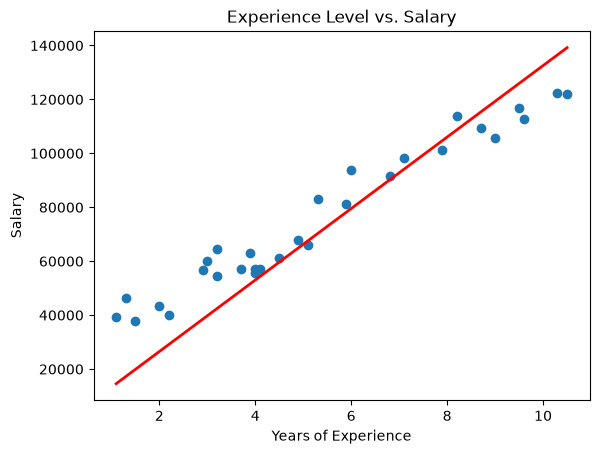

In [ ]:
# Create the scatterplot
plt.scatter(df["YearsExperience"], df["Salary"])

# Draw the regression line
plt.plot(
    df["YearsExperience"],
    results.predict(),
    color='red',
    linewidth=2,
    label='Regression Line'
)

# Add your labels!
plt.title("Experience Level vs. Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary (USD)")


### Logistic Regression

How does the years of experience affect whether or not someone is promoted?

IV: years of experience
DP: whether or not someone is promoted

In [19]:
df.head()

,YearsExperience,Salary,promoted
0,1.1,39343.0,0
1,1.3,46205.0,0
2,1.5,37731.0,0
3,2.0,43525.0,1
4,2.2,39891.0,0


In [20]:
import statsmodels.formula.api as smf

In [21]:
model = smf.logit(formula='promoted ~ YearsExperience', data=df)
results = model.fit()

Optimization terminated successfully.
         Current function value: 0.635838
         Iterations 5


In [22]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               promoted   No. Observations:                   30
Model:                          Logit   Df Residuals:                       28
Method:                           MLE   Df Model:                            1
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                 0.05523
Time:                        16:25:40   Log-Likelihood:                -19.075
converged:                       True   LL-Null:                       -20.190
Covariance Type:            nonrobust   LLR p-value:                    0.1353
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.6752      0.826     -0.817      0.414      -2.294       0.944
YearsExperience     0.2107      0.148      1.423      0.155      -0.079       0.501
===================================================================================
"""

### Can GPA predict SAT scores?

In [23]:
school_data = pd.read_csv("../data/sat_gpa.csv")

In [24]:
school_data.head()

,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83


In [ ]:
X = school_data["GPA"]
y = school_data["SAT"]

X = sm.add_constant(X)

model = sm.OLS(y, X)
results = model.fit()
results.summary()


# SAT SCORE =  1043 + 240.35(GPA)

# The predicted change in SAT score for every 1 unit change in GPA is 240.
# 37.5% of the variation in the SAT score is explained by GPA
# My p-value is < 0.05 so I reject the null hypothesis and declare that my result is significant.



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    SAT   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.369
Method:                 Least Squares   F-statistic:                     58.86
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.26e-11
Time:                        16:45:34   Log-Likelihood:                -579.94
No. Observations:                 100   AIC:                             1164.
Df Residuals:                      98   BIC:                             1169.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1043.0474    105.593      9.878      0.000     833.501    1252.594
GPA          240.3549     31.330      7.672      0.000     178.182     302.528
==============================================================================
Omnibus:                        0.326   Durbin-Watson:                   2.349
Prob(Omnibus):                  0.849   Jarque-Bera (JB):                0.379
Skew:                          -0.132   Prob(JB):                        0.828
Kurtosis:                       2.854   Cond. No.                         48.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Fill in the blank: \

Your model explains ________ of the variation in house prices, and  explanatory variables are statistically significant.